# 04 · Edges, markers, and watershed

**Level:** intermediate. **Time:** 50–70 minutes. **Prerequisites:** thresholding, connected components, and 2D indexing. This notebook runs independently and offline on the CPU.

**You will:** distinguish an edge map from an object mask; calculate distance to background; place markers; separate touching objects; diagnose undersegmentation and oversegmentation; apply intensity markers to a real image.

**Core question:** what evidence tells us that one connected region contains multiple objects?


In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "learning" / "data.py").is_file()), None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook inside the complete ImageSegmentationPractical folder.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (10, 3.5), "image.cmap": "gray",
                     "axes.spines.top": False, "axes.spines.right": False})
print("Project:", PROJECT_ROOT.name)


Project: ImageSegmentationPractical


## 1. Create two touching objects

Two synthetic disks overlap in the image plane, producing one connected foreground region. Their true generating centers are known to us, but the main algorithm will use the observed foreground only. The overlap has no unique pixel-level instance ownership unless we define a convention, so we avoid claiming a perfect instance ground-truth mask.


In [2]:
from scipy import ndimage as ndi
from skimage import filters, feature, measure, segmentation, color, data, util

yy, xx = np.mgrid[:128, :160]
disk_a = (yy - 64)**2 + (xx - 57)**2 <= 29**2
disk_b = (yy - 64)**2 + (xx - 101)**2 <= 29**2
foreground_truth = disk_a | disk_b
rng = np.random.default_rng(13)
observation = np.clip(0.15 + 0.65 * foreground_truth + rng.normal(0, 0.045, yy.shape), 0, 1)
smooth = filters.gaussian(observation, sigma=1)
foreground = smooth > filters.threshold_otsu(smooth)
components = measure.label(foreground, connectivity=2)
print("Generating disks: 2; thresholded connected components:", components.max())

def show_grid(images, titles, columns=3, cmap="gray", limits=None):
    """A small display helper; every array is still available for inspection."""
    rows = (len(images) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(4 * columns, 3.4 * rows), squeeze=False)
    for ax, image, title in zip(axes.flat, images, titles):
        kwargs = {} if limits is None else {"vmin": limits[0], "vmax": limits[1]}
        ax.imshow(image, cmap=cmap, **kwargs)
        ax.set_title(title)
        ax.axis("off")
    for ax in list(axes.flat)[len(images):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


Generating disks: 2; thresholded connected components: 1


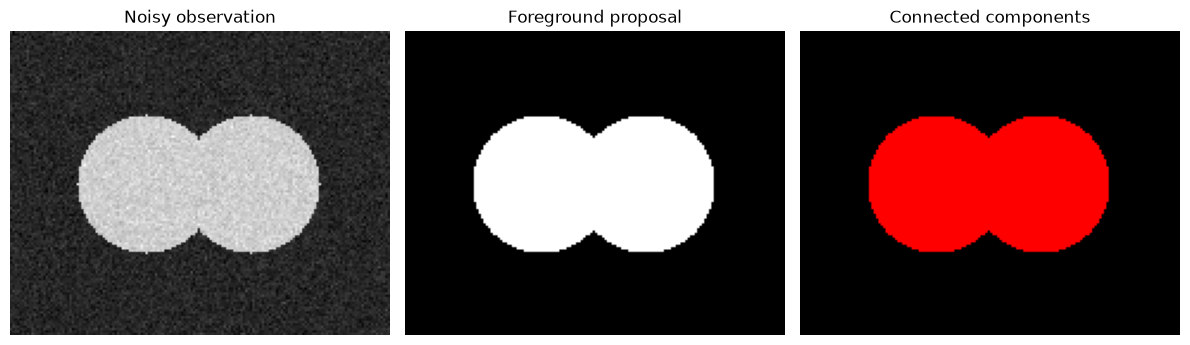

In [3]:
show_grid([observation, foreground, color.label2rgb(components, bg_label=0)],
          ["Noisy observation", "Foreground proposal", "Connected components"])


## 2. Edges are evidence, not filled objects

The Sobel filter estimates intensity change. Canny returns selected thin edges after smoothing and edge-strength decisions. Neither output directly assigns every object pixel an instance ID. Broken boundaries can leak; internal texture can create extra boundaries.

**Observe:** there is little intensity evidence at the overlap between identical disks. An edge detector cannot invent that hidden boundary.


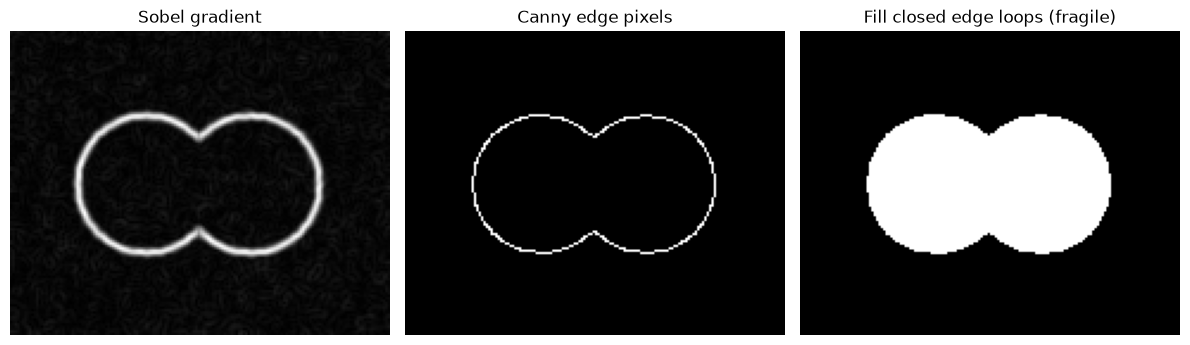

In [4]:
gradient = filters.sobel(smooth)
edges = feature.canny(observation, sigma=1.4, low_threshold=0.08, high_threshold=0.18)
filled_edges = ndi.binary_fill_holes(edges)
show_grid([gradient, edges, filled_edges],
          ["Sobel gradient", "Canny edge pixels", "Fill closed edge loops (fragile)"])


## 3. Distance transform: turn shape into a surface

For each foreground pixel, the Euclidean distance transform measures distance to the nearest background pixel. Large values often occur near object centers. Negating this map produces basins: deep near centers, shallow near boundaries. Watershed can grow an object outward from each basin's marker.

This uses a **shape assumption**. It works well for some round touching objects and can fail for branched, elongated, or heavily overlapping ones.


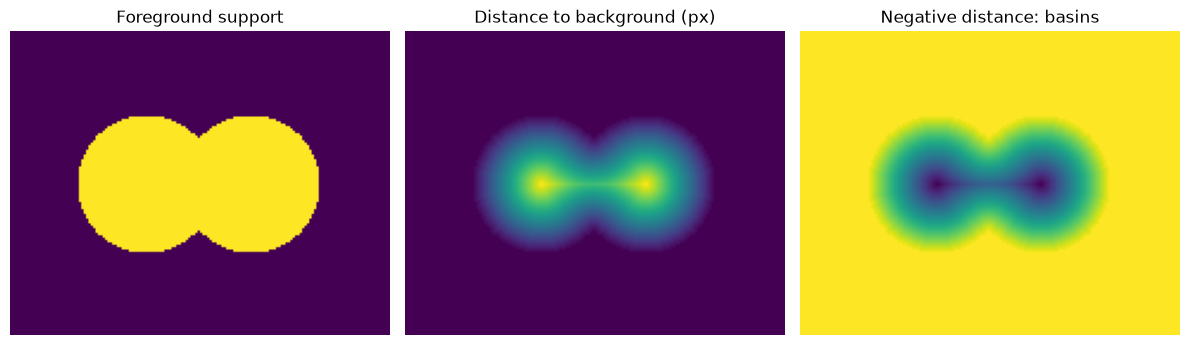

Largest foreground distance: 29.00 pixels


In [5]:
distance = ndi.distance_transform_edt(foreground)
show_grid([foreground, distance, -distance],
          ["Foreground support", "Distance to background (px)", "Negative distance: basins"], cmap="viridis")
print(f"Largest foreground distance: {distance.max():.2f} pixels")


## 4. Convert peaks into labeled markers

`peak_local_max` returns coordinate pairs. We put a unique positive integer at each coordinate and keep 0 elsewhere. `min_distance` limits how closely peaks may occur. A marker is a seed for one proposed object, not an object boundary.

Marker count is a modeling decision: too few seeds tend to merge objects; too many tend to split them.


Marker coordinates (row, column): [[64, 57], [64, 101]]


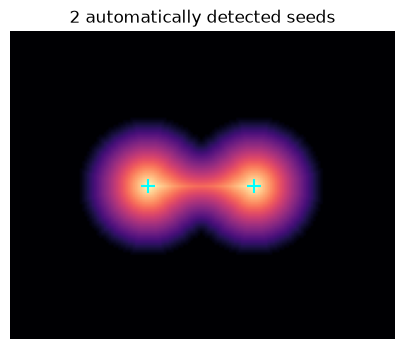

In [6]:
def markers_from_distance(distance_map, mask, min_distance=15):
    coordinates = feature.peak_local_max(
        distance_map, min_distance=min_distance, labels=mask.astype(np.uint8),
        exclude_border=False,
    )
    markers = np.zeros(mask.shape, dtype=np.int32)
    for marker_id, (row, col) in enumerate(coordinates, start=1):
        markers[row, col] = marker_id
    return markers, coordinates

markers, coordinates = markers_from_distance(distance, foreground, min_distance=15)
print("Marker coordinates (row, column):", coordinates.tolist())
fig, ax = plt.subplots(figsize=(7, 4))
ax.imshow(distance, cmap="magma")
ax.scatter(coordinates[:, 1], coordinates[:, 0], marker="+", color="cyan", s=100)
ax.set_title(f"{len(coordinates)} automatically detected seeds")
ax.axis("off")
plt.show()


## 5. Flood the basins

The mask confines flooding to the foreground. With `watershed_line=True`, a separating line receives label 0. Those zero pixels lie **inside** the foreground support and should not silently be interpreted as missed foreground when evaluating the instance separation. Here we visualize the line explicitly.


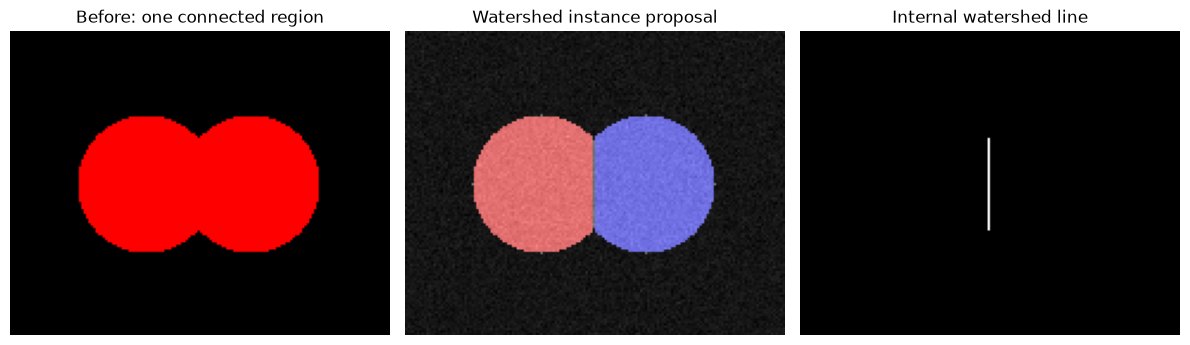

Proposed instances: 2
Areas: {1: 2430, 2: 2430}


In [7]:
instances = segmentation.watershed(-distance, markers, mask=foreground, watershed_line=True)
colored = color.label2rgb(instances, image=observation, bg_label=0, alpha=0.45)
internal_line = foreground & (instances == 0)
show_grid([color.label2rgb(components, bg_label=0), colored, internal_line],
          ["Before: one connected region", "Watershed instance proposal", "Internal watershed line"])
instance_ids = np.unique(instances)
instance_ids = instance_ids[instance_ids != 0]
print("Proposed instances:", len(instance_ids))
print("Areas:", {int(i): int((instances == i).sum()) for i in instance_ids})


## 6. Controlled failure experiment: marker count

We deliberately supply one, two, and three markers in the same foreground. These are manual hints chosen using the synthetic construction and are **not** an automatic detector. Compare the resulting boundaries. Watershed faithfully follows seeds even when the seeds describe the wrong number of objects.


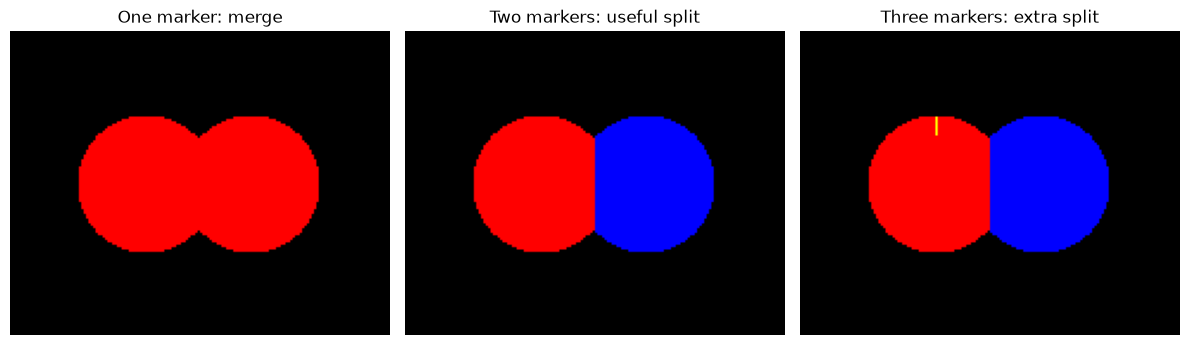

In [8]:
seed_sets = {
    "One marker: merge": [(64, 57)],
    "Two markers: useful split": [(64, 57), (64, 101)],
    "Three markers: extra split": [(64, 57), (64, 101), (43, 57)],
}
marker_results = []
for title, seeds in seed_sets.items():
    manual_markers = np.zeros(foreground.shape, dtype=np.int32)
    for label_id, (row, col) in enumerate(seeds, 1):
        manual_markers[row, col] = label_id
    result = segmentation.watershed(-distance, manual_markers, mask=foreground)
    marker_results.append(color.label2rgb(result, bg_label=0))
show_grid(marker_results, list(seed_sets))


## 7. Sweep peak spacing

Increase `min_distance` until the second peak is suppressed. This parameter is in pixels, so a fixed value is not scale invariant. A stable object count across a useful range is encouraging, but a correct count alone does not validate boundaries or identity.


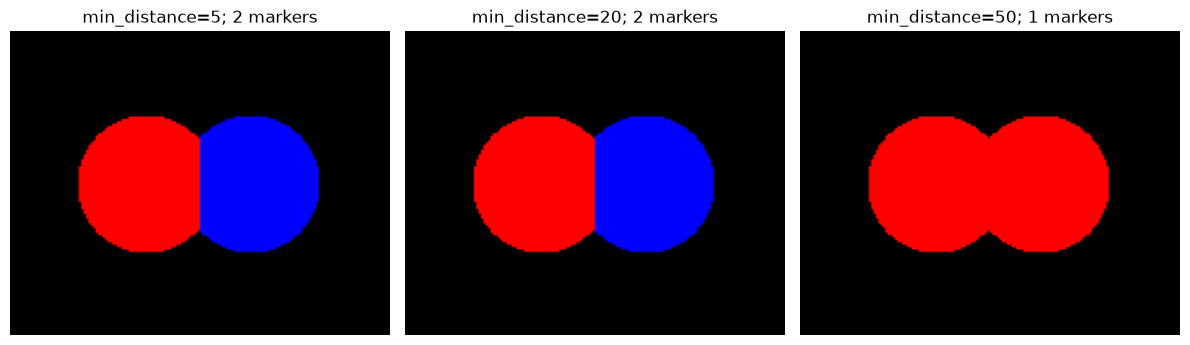

In [9]:
spacing_results, spacing_titles = [], []
for spacing in (5, 20, 50):
    trial_markers, trial_coordinates = markers_from_distance(distance, foreground, spacing)
    trial_instances = segmentation.watershed(-distance, trial_markers, mask=foreground)
    spacing_results.append(color.label2rgb(trial_instances, bg_label=0))
    spacing_titles.append(f"min_distance={spacing}; {len(trial_coordinates)} markers")
show_grid(spacing_results, spacing_titles)


## 8. Another formulation: markers on a gradient

For a real coin photograph, assign dark pixels as likely background and bright pixels as likely foreground, leaving ambiguous pixels unmarked. Watershed on a gradient grows these two semantic regions. These seeds use brightness heuristics, not annotations; a bright background or dark coin interior can be mislabeled.

This is **foreground/background segmentation**, not a complete coin-instance detector. The packaged image has no reference annotation in this lesson.


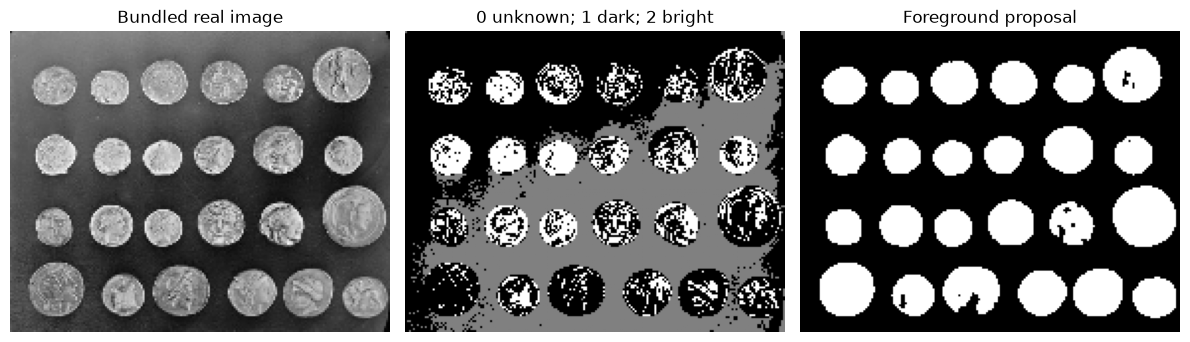

Inspect seed mistakes first when the final region looks wrong.


In [10]:
coins = util.img_as_float(data.coins())[::2, ::2]
coin_gradient = filters.sobel(filters.gaussian(coins, sigma=1))
intensity_markers = np.zeros(coins.shape, dtype=np.int32)
intensity_markers[coins < 0.25] = 1  # background seed class
intensity_markers[coins > 0.65] = 2  # foreground seed class
coin_regions = segmentation.watershed(coin_gradient, intensity_markers)
show_grid([coins, intensity_markers, coin_regions == 2],
          ["Bundled real image", "0 unknown; 1 dark; 2 bright", "Foreground proposal"])
print("Inspect seed mistakes first when the final region looks wrong.")


## 9. Exercises

**A. Edge smoothing.** Compare Canny with sigma 0.5, 1.5, and 3.0. Which setting retains noise? Which can move or remove small edges?

<details><summary>Worked solution A</summary>

```python
edge_maps = [feature.canny(observation, sigma=s) for s in (0.5, 1.5, 3.0)]
show_grid(edge_maps, ["sigma 0.5", "sigma 1.5", "sigma 3.0"])
```
Low smoothing preserves more intensity fluctuations. High smoothing reduces noise but may weaken small features. No setting reveals a boundary absent from the measured intensities.
</details>


**B. Why is the mask essential?** Run distance watershed once with the foreground mask and once without it. Inspect what happens to background pixels.

<details><summary>Worked solution B</summary>

```python
bounded = segmentation.watershed(-distance, markers, mask=foreground)
unbounded = segmentation.watershed(-distance, markers)
show_grid([color.label2rgb(bounded, bg_label=0), color.label2rgb(unbounded, bg_label=0)],
          ["Confined to foreground", "Flooded background too"], columns=2)
```
Without a mask, the algorithm is asked to label the whole image. This is sometimes intended, but it does not match the instance task we defined here.
</details>


**C. Avoid a misleading foreground score.** Compute foreground IoU using a watershed with `watershed_line=False`. Compare it to the IoU of the original threshold mask. Does this metric tell you whether the disks were separated correctly?

<details><summary>Worked solution C</summary>

```python
no_line = segmentation.watershed(-distance, markers, mask=foreground, watershed_line=False)
def iou(a, b):
    union = (a | b).sum()
    return (a & b).sum() / union if union else 1.0
print(iou(foreground_truth, foreground))
print(iou(foreground_truth, no_line > 0))
```
With seeds covering this connected foreground, the foreground support is unchanged. Both scores are equal even if you use the wrong number of markers. Instance evaluation requires matching or comparing object partitions, which later lessons introduce.
</details>


## Common mistakes and completion checklist

- An edge map is not a filled semantic mask.
- Distance watershed expects `-distance` when centers should be basins.
- Coordinate order is `(row, column)`; scatter plots use `(x=column, y=row)`.
- Missing or extra markers create missing or extra instances.
- One object count does not establish segmentation accuracy.
- A real image without labels supports visual diagnosis, not a claimed accuracy score.

- [ ] I can explain why connected components merged the disks.
- [ ] I can construct markers from peak coordinates.
- [ ] I can distinguish foreground segmentation from instance separation.
- [ ] I have demonstrated both marker failure modes.
- [ ] I completed A–C and described one limitation of watershed.

**Next:** notebook 05 groups pixels by feature similarity and builds superpixels.


## Official references

- [Watershed example and distance-transform construction](https://scikit-image.org/docs/stable/auto_examples/segmentation/plot_watershed.html)
- [Watershed parameters](https://scikit-image.org/docs/stable/api/skimage.segmentation.html#skimage.segmentation.watershed)
- [Peak detection API](https://scikit-image.org/docs/stable/api/skimage.feature.html#skimage.feature.peak_local_max)
- [Canny edge detector](https://scikit-image.org/docs/stable/auto_examples/edges/plot_canny.html)
- [SciPy Euclidean distance transform](https://docs.scipy.org/doc/scipy/reference/generated/scipy.ndimage.distance_transform_edt.html)
